# Logistic regression / Hồi quy logistic

Tôi lưu bài này trong nhật ký học để ôn lại cách viết và đọc code.

**Nguồn / Source:** Bản Colab `Bản sao của Simple_LogisticRegression.ipynb`. Các bài có tên “Bản sao” là tài liệu thực hành tham khảo; tên file không được xem là bằng chứng tác giả.

**Cách dùng / Run:** chạy các cell theo thứ tự. Thư viện được dùng: `__future__`, `matplotlib.pyplot`, `numpy`, `scipy.spatial.distance`, `seaborn`, `sklearn.metrics`.

**Execution:** ARCHIVED_SOURCE — bản mã học tập, chưa ghi nhận chạy lại đầy đủ trong đợt này. Output lịch sử được bỏ; hướng dẫn và lỗi cần xử lý nằm trong bảng kỹ thuật.

Learning archive: coursework/tutorial practice, with original code retained for study. Original tutorial references embedded in the source are retained below.

# Một ví dụ đơn giản về việc giải bài toán Logistic Regression trong Python.


### Ví dụ với dữ liệu 1 chiều
Quay trở lại với ví dụ nêu ở phần Giới thiệu. Trước tiên ta cần khai báo vài thư viện và tạo dữ liệu:


In [1]:
from __future__ import division, print_function, unicode_literals
import numpy as np #Imports necessary libraries: It imports numpy for numerical operations, matplotlib.pyplot for plotting, and cdist from scipy.spatial.distance.
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
np.random.seed(22) #Sets random seed: np.random.seed(22) ensures that the random numbers generated are the same each time the code is run, making the results reproducible.

X = np.array([[0.50, 0.75, 1.00, 1.25, 1.50, 1.75, 1.75, 2.00, 2.25, 2.50,
              2.75, 3.00, 3.25, 3.50, 4.00, 4.25, 4.50, 4.75, 5.00, 5.50]]) #Defines input data (X) and output labels (y): X is a NumPy array representing the input feature (studying hours).
y = np.array([0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1]) #y is a NumPy array representing the corresponding output labels (0 for fail, 1 for pass).

X = np.concatenate((np.ones((1, X.shape[1])), X), axis = 0) #Adds a bias term to X: X = np.concatenate((np.ones((1, X.shape[1])), X), axis = 0)) adds a row of ones to the beginning of the X array. This is a common technique in machine learning to incorporate a bias term into the model, allowing the logistic regression line to shift vertically.

### Các hàm cần thiết cho logistic sigmoid regression

In [2]:
def sigmoid(s):
    return 1/(1 + np.exp(-s)) #This function computes the sigmoid activation, The sigmoid function squashes any input value to a value between 0 and 1, making it suitable for representing probabilities.
#Parameters
def logistic_sigmoid_regression(X, y, w_init, alp, tol = 1e-4, max_count = 10000): #This function implements the logistic regression algorithm using gradient descent. Parameters:X: The input data with the bias term.
# X: The input data with the bias term.
#y: The true labels.
#w_init: The initial weight vector.
#alp: The learning rate, controlling the step size during weight updates.
#tol: The tolerance level for the stopping criterion (when the change in weights is small).
#max_count: The maximum number of iterations for gradient descent.'''
#Process
    w = [w_init] #It initializes the weights w with w_init.
    it = 0
    N = X.shape[1] #
    d = X.shape[0]
    count = 0
    check_w_after = 20
    while count < max_count:
#         it += 1
        # mix data
        mix_id = np.random.permutation(N)#In each iteration, it shuffles the data (mix_id) and iterates through each data point (xi, yi).
        for i in mix_id: #For each data point, it calculates the predicted probability (zi) using the current weights and the sigmoid function.
            xi = X[:, i].reshape(d, 1)
            yi = y[i]
            zi = sigmoid(np.dot(w[-1].T, xi))
            w_new = w[-1] + alp*(yi - zi)*xi
            count += 1
            # stopping criteria
            if count%check_w_after == 0: # It checks for convergence every check_w_after iterations by comparing the change in weights with the tolerance (tol). If the change is below the tolerance, the algorithm stops and returns the list of weight updates.
                if np.linalg.norm(w_new - w[-check_w_after]) < tol: #If the maximum number of iterations is reached without convergence, it returns the list of weight updates up to that point.
                    return w
            w.append(w_new)
    return w

In [3]:
alp = .05 # Sets the learning rate (alp) to 0.05. The learning rate determines the step size taken during gradient descent.
d = X.shape[0] #Gets the number of features (including the bias term) from the shape of the input data X and stores it in d.
w_init = np.random.randn(d, 1) #nitializes the weight vector (w_init) with random values drawn from a standard normal distribution. The shape of the weight vector is d rows and 1 column, corresponding to the number of features.

w = logistic_sigmoid_regression(X, y, w_init, alp) #Calls the logistic_sigmoid_regression function with the input data X, true labels y, initial weights w_init, and learning rate alp. The function trains the logistic regression model and returns a list of weight updates, which is stored in the variable w.
print(w[-1]) #rints the final weight vector (the last element in the w list) after the logistic regression algorithm has finished training. This final weight vector contains the learned parameters of the model.

[[-4.1037492 ]
 [ 1.57227859]]


### Với kết quả tìm được, đầu ra \\(y\\) có thể được dự đoán theo công thức: `y = sigmoid(-4.1 + 1.537*x)`. Với dữ liệu trong tập training, kết quả là:

In [4]:
print(sigmoid(np.dot(w[-1].T, X))) #calculates and prints the predicted probabilities of passing based on the trained logistic regression model. w[-1].T takes the transpose of the final weight vector obtained from the logistic regression.
#np.dot(w[-1].T, X) performs a matrix multiplication between the transposed weight vector and the input data X. This calculates the linear combination of the weights and features for each data point (w0 + w1*x in this case).
#sigmoid(...) applies the sigmoid function to the result of the dot product. This transforms the linear combination into a probability value between 0 and 1, representing the predicted probability of the student passing for each given studying hour.
# This displays the calculated predicted probabilities for all the data points in the training set.

[[0.03497198 0.0509537  0.07368121 0.10542009 0.14863702 0.20550086
  0.20550086 0.27704    0.36213205 0.45684447 0.55478342 0.64864457
  0.73226724 0.80206102 0.89892758 0.92946072 0.95127006 0.96657886
  0.9771936  0.98947877]]


Biểu diễn kết quả này trên đồ thị ta có:

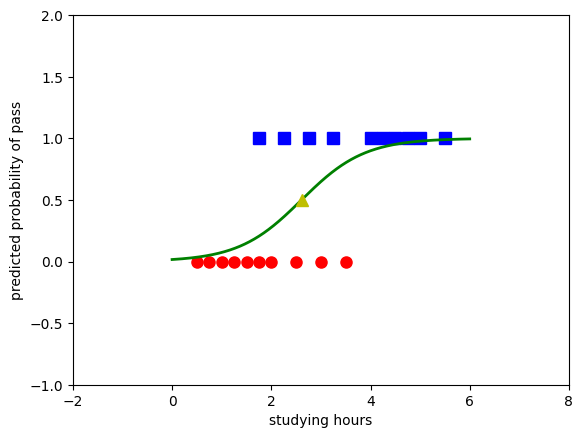

In [5]:
#Separates data by class: It separates the input data X and true labels y into two groups: those where y is 0 (fail) and those where y is 1 (pass).
X0 = X[1, np.where(y == 0)][0] #
y0 = y[np.where(y == 0)]
X1 = X[1, np.where(y == 1)][0]
y1 = y[np.where(y == 1)]

#Plots the original data point
plt.plot(X0, y0, 'ro', markersize = 8) #plt.plot(X0, y0, 'ro', markersize = 8) plots the 'fail' data points as red circles.
plt.plot(X1, y1, 'bs', markersize = 8) #plt.plot(X1, y1, 'bs', markersize = 8) plots the 'pass' data points as blue squares.

#Generates points for the sigmoid curve:
xx = np.linspace(0, 6, 1000) #creates an array of 1000 evenly spaced values between 0 and 6, representing the range of studying hours for plotting the sigmoid curve.
w0 = w[-1][0][0] #extract the learned weights from the final weight vector w[-1]. w0 is the bias term and w1 is the weight for studying hours.
w1 = w[-1][1][0]
threshold = -w0/w1
yy = sigmoid(w0 + w1*xx) #calculates the predicted probabilities (yy) for each value in xx using the sigmoid function and the learned weights. This generates the points for the sigmoid curve.
plt.axis([-2, 8, -1, 2]) #sets the limits for the x and y axes of the plot.
# Plots the sigmoid curve and decision boundary
plt.plot(xx, yy, 'g-', linewidth = 2) #plots the calculated sigmoid curve as a green line.
plt.plot(threshold, .5, 'y^', markersize = 8) #plots a yellow triangle at the decision boundary on the sigmoid curve, indicating where the probability is 0.5.
plt.xlabel('studying hours')
plt.ylabel('predicted probability of pass')
plt.savefig('lg_results.png', bbox_inches='tight', dpi = 300) #saves the plot as a PNG image file.
plt.show()

Nếu như chỉ có hai output là 'fail' hoặc 'pass', điểm trên đồ thị của hàm sigmoid tương ứng với xác suất 0.5 được chọn làm _hard threshold_ (ngưỡng cứng).

Đưa tỉ lệ về đúng dạng của nhãn

In [6]:
#converts the predicted probabilities from the logistic regression model into binary class labels and prepares the true labels for evaluation
y_hat = sigmoid(np.dot(w[-1].T, X)) #This line recalculates the predicted probabilities using the final learned weights (w[-1]) and the input data (X). This is the same calculation performed in a previous cell to get the probabilities.
y_pred = (y_hat >= 0.5).astype(int).reshape(-1) #This is where the predicted probabilities are converted into binary class labels:y_hat >= 0.5 creates a boolean array where True indicates a predicted probability of 0.5 or greater, and False indicates a probability less than 0.5.astype(int) converts this boolean array into an integer array, where True becomes 1 and False becomes 0. These are the predicted class labels ('pass' or 'fail').
y_true = y.reshape(-1) #reshapes the array into a 1-dimensional array.

Nhận xét kết quả


Accuracy : 0.80
Precision: 0.80
Recall   : 0.80
F1-score : 0.80
Confusion Matrix:


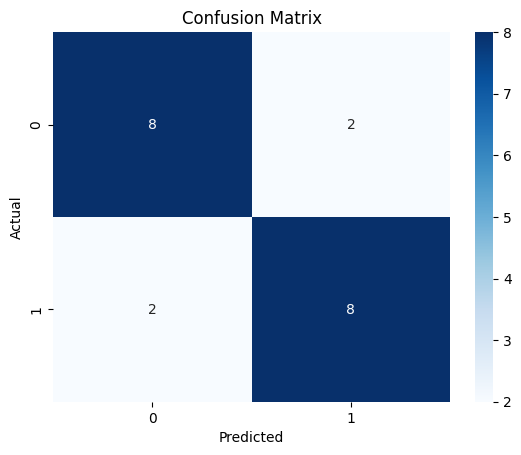

In [7]:
# evaluates the performance of the logistic regression model using several common metrics and visualizes the results with a confusion matrix:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score #This line imports necessary functions from the sklearn.metrics module
import seaborn as sns #This line imports the seaborn library, which is used for creating informative statistical graphics. It's used here to create a heatmap for the confusion matrix.

cm = confusion_matrix(y_true, y_pred) # Used to compute a confusion matrix, a table that summarizes the performance of a classification model.Computes the confusion matrix using the true labels (y_true) and the predicted labels (y_pred).
acc = accuracy_score(y_true, y_pred) #Calculates the accuracy of the model, which is the proportion of correctly classified instances.
pre = precision_score(y_true, y_pred, average='binary') #Calculates the precision, which is the ratio of true positive predictions to the total predicted positives.
rec = recall_score(y_true, y_pred, average='binary') #Calculates the recall (or sensitivity), which is the ratio of true positive predictions to the total actual positives.
f1 = f1_score(y_true, y_pred, average='binary') #Calculates the F1-score, which is the harmonic mean of precision and recall.

#These lines print the calculated evaluation metrics (accuracy, precision, recall, and F1-score) formatted to two decimal places.
print(f"\nAccuracy : {acc:.2f}")
print(f"Precision: {pre:.2f}")
print(f"Recall   : {rec:.2f}")
print(f"F1-score : {f1:.2f}")

print("Confusion Matrix:") #Prints a header for the confusion matrix visualization.
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues') #Creates a heatmap visualization of the confusion matrix:
plt.xlabel('Predicted') #Labels the x and y axes of the heatmap.
plt.ylabel('Actual') #Labels the x and y axes of the heatmap.
plt.title('Confusion Matrix') #Sets the title of the heatmap.
plt.show() #Displays the generated plot.


## Ghi chú học tập / Study prompts

- Đầu vào của từng hàm là gì, đầu ra có kiểu và kích thước nào?
- Thay đổi tham số hoặc dữ liệu nhỏ sẽ ảnh hưởng kết quả ra sao?
- Cell nào cần dữ liệu bên ngoài, thư viện hoặc thao tác nhập tay?

Explain the data flow, modify one example, and record the result when revisiting this exercise.

In [8]:
LAB_RESULT = {'execution': 'all source cells completed'}